In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import  DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/machine learning/praktikum05/data/stunting_wasting_dataset.xlsx')
df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,Tall,Risk of Overweight
1,Laki-laki,20,77.7,8.5,Stunted,Underweight
2,Laki-laki,10,79.0,10.3,Normal,Risk of Overweight
3,Perempuan,2,50.3,8.3,Severely Stunted,Risk of Overweight
4,Perempuan,5,56.4,10.9,Severely Stunted,Risk of Overweight


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Jenis Kelamin      100000 non-null  object 
 1   Umur (bulan)       100000 non-null  int64  
 2   Tinggi Badan (cm)  100000 non-null  float64
 3   Berat Badan (kg)   100000 non-null  float64
 4   Stunting           100000 non-null  object 
 5   Wasting            100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [ ]:
df.isnull().sum()

,0
Jenis Kelamin,0
Umur (bulan),0
Tinggi Badan (cm),0
Berat Badan (kg),0
Stunting,0
Wasting,0


In [ ]:
df.duplicated().sum()

np.int64(7308)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.rename(columns={
    'jendela kelamin':'jenis_kelamin' ,
    'umur (bulan)': 'umur_bulan',
    'tinggi badan (cm)': 'tinggi_cm',
    'berat badan (kg)': 'berat_kg' ,
    'stunting': 'stunting',
    'wasting': 'wasting'
})

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92692 entries, 0 to 99997
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Jenis Kelamin      92692 non-null  object 
 1   Umur (bulan)       92692 non-null  int64  
 2   Tinggi Badan (cm)  92692 non-null  float64
 3   Berat Badan (kg)   92692 non-null  float64
 4   Stunting           92692 non-null  object 
 5   Wasting            92692 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 5.0+ MB


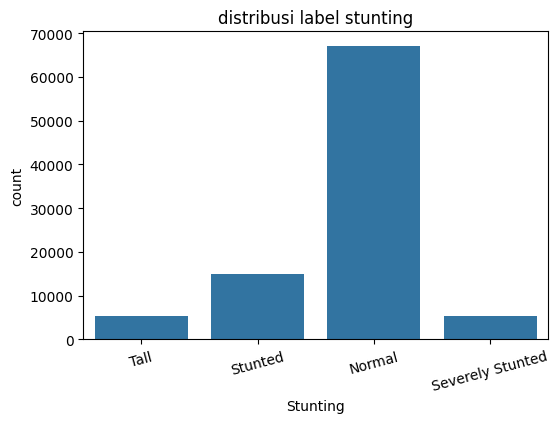

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Stunting', data=df)
plt.title('distribusi label stunting')
plt.xticks(rotation=15)
plt.show()

In [ ]:
stunting_cat = df['Stunting'].astype('category')
stunting_classses = list(stunting_cat.cat.categories)
df['Stunting'] = stunting_cat.cat.codes


for col in ['jenis_kelamin', 'wasting ']:
  if col in df.columns:
    df[col] = df[col].astype('category').cat.codes



df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,3,Risk of Overweight
1,Laki-laki,20,77.7,8.5,2,Underweight
2,Laki-laki,10,79.0,10.3,0,Risk of Overweight
3,Perempuan,2,50.3,8.3,1,Risk of Overweight
4,Perempuan,5,56.4,10.9,1,Risk of Overweight


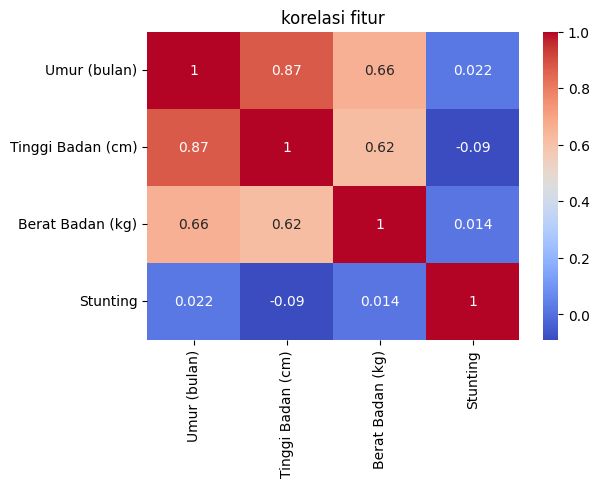

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('korelasi fitur')
plt.show()

In [ ]:
# Rename columns using the actual exact names present in the DataFrame
df = df.rename(columns={
    'Jenis Kelamin': 'jenis_kelamin',
    'Umur (bulan)': 'umur_bulan',
    'Tinggi Badan (cm)': 'tinggi_cm',
    'Berat Badan (kg)': 'berat_kg',
    'Stunting': 'stunting',
    'Wasting': 'wasting'
})

# Encode categorical columns to numeric if not already done
for col in ['jenis_kelamin', 'wasting']:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].astype('category').cat.codes

# Memilih fitur dan target
feature_cols = [
    'umur_bulan',
    'tinggi_cm',
    'berat_kg',
    'wasting'
]

X = df[feature_cols]
y = df['stunting']


In [ ]:
# Membagi dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

len(X_train), len(X_test)

(74153, 18539)

In [ ]:
# Membangun model
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
# Evaluasi
y_pred = dt.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(
    y_test,
    y_pred,
    target_names=stunting_classses,
    zero_division=0
))

Akurasi: 77.67 %

Confusion Matrix:
 [[12901     0   481    29]
 [  587    25   455     0]
 [ 1653     0  1355     0]
 [  935     0     0   118]]

Classification Report:
                   precision    recall  f1-score   support

          Normal       0.80      0.96      0.88     13411
Severely Stunted       1.00      0.02      0.05      1067
         Stunted       0.59      0.45      0.51      3008
            Tall       0.80      0.11      0.20      1053

        accuracy                           0.78     18539
       macro avg       0.80      0.39      0.41     18539
    weighted avg       0.78      0.78      0.73     18539



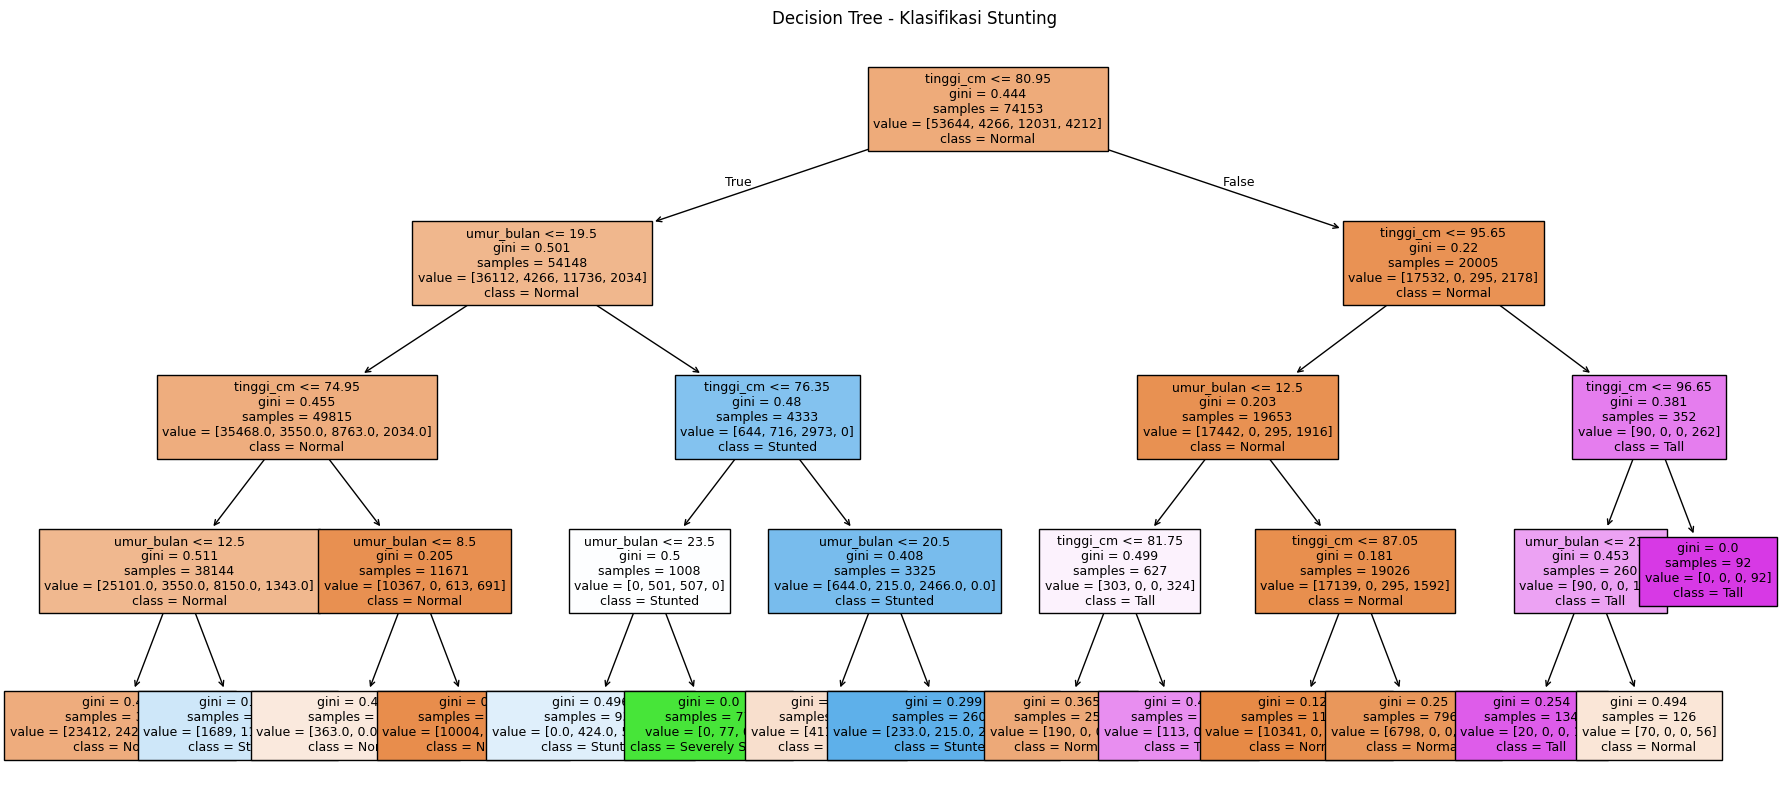

In [ ]:
# Visualisasi model
plt.figure(figsize=(22, 10))

plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=stunting_classses,
    filled=True,
    fontsize=9
)

plt.title("Decision Tree - Klasifikasi Stunting")
plt.show()

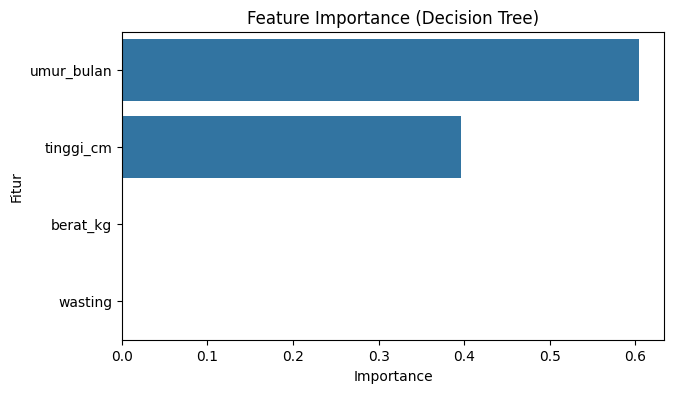

,0
umur_bulan,0.603752
tinggi_cm,0.396248
berat_kg,0.000000
wasting,0.000000


In [ ]:
# Fitur yang penting
imp = pd.Series(
    dt.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

plt.figure(figsize=(7, 4))

sns.barplot(x=imp, y=imp.index)

plt.title("Feature Importance (Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Fitur")

plt.show()

imp

In [ ]:
scores = {}

for d in range(2, 9):
    m = DecisionTreeClassifier(
        max_depth=d,
        random_state=42
    )

    m.fit(X_train, y_train)

    scores[d] = accuracy_score(
        y_test,
        m.predict(X_test)
    )

print(scores)

best_d = max(scores, key=scores.get)

print(
    "Best max_depth:", best_d,
    "| Acc:", round(scores[best_d] * 100, 2), "%"
)

{2: 0.7571605803980798, 3: 0.757106640056098, 4: 0.7766869841954798, 5: 0.7840228707050003, 6: 0.8174119423917148, 7: 0.8237769027455634, 8: 0.8422244997033281}
Best max_depth: 8 | Acc: 84.22 %


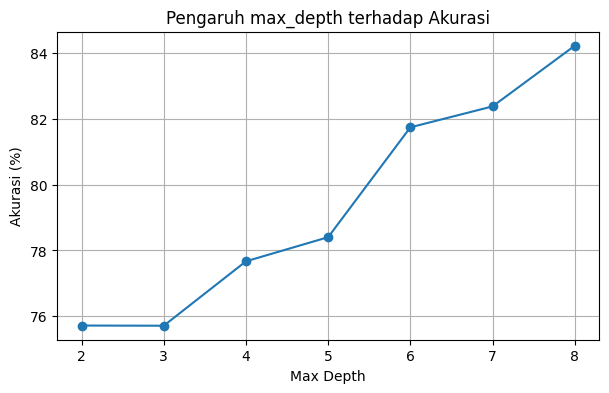

In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(
    list(scores.keys()),
    [v * 100 for v in scores.values()],
    marker='o'
)

plt.title("Pengaruh max_depth terhadap Akurasi")
plt.xlabel("Max Depth")
plt.ylabel("Akurasi (%)")
plt.xticks(list(scores.keys()))
plt.grid(True)

plt.show()

In [ ]:
# Membaca dataset Iris
df_iris = pd.read_csv(
    '/content/drive/MyDrive/machine learning/praktikum05/data/dataset_iris.csv'
)

df_iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
df_iris.info()

print(df_iris.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [ ]:
# Menentukan kolom target
target_candidates = ['species', 'variety']

target_col = next(
    (
        col for col in df_iris.columns
        if col.strip().lower() in target_candidates
    ),
    None
)

if target_col is None:
    raise ValueError(
        "Kolom species/variety tidak ditemukan. "
        "Periksa nama kolom pada dataset."
    )

# Menghapus data kosong
df_iris = df_iris.dropna().copy()

# Memilih fitur numerik
feature_cols = [
    col for col in df_iris.select_dtypes(include='number').columns
    if col.lower() not in ['id']
]

X = df_iris[feature_cols]
y = df_iris[target_col]

print("Fitur:", feature_cols)
print("Target:", target_col)
print("Jumlah data:", len(df_iris))
print("Spesies:", y.unique())

Fitur: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Target: Species
Jumlah data: 150
Spesies: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 120
Jumlah data testing: 30


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_iris = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

dt_iris.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_pred = dt_iris.predict(X_test)

print(
    "Akurasi:",
    round(accuracy_score(y_test, y_pred) * 100, 2),
    "%"
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=dt_iris.classes_))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi: 93.33 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



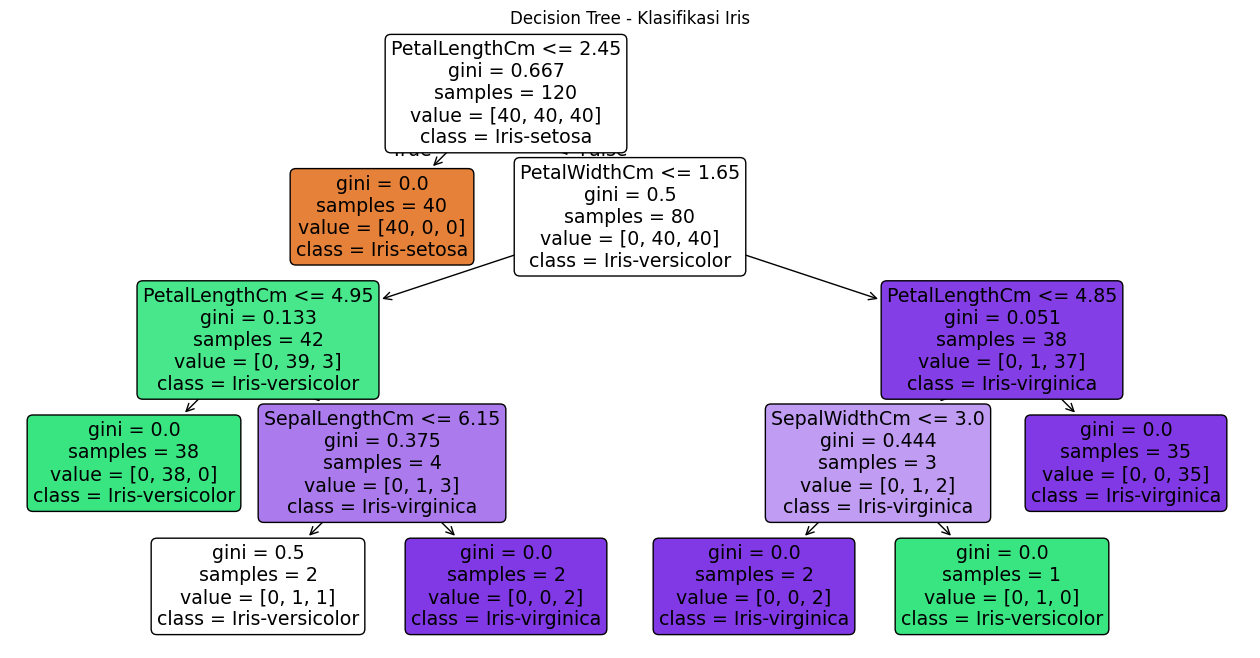

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    dt_iris,
    feature_names=feature_cols,
    class_names=[str(c) for c in dt_iris.classes_],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Klasifikasi Iris")
plt.show()

In [ ]:
# Membandingkan hasil aktual dengan prediksi
hasil_iris = X_test.copy()

hasil_iris['Species_Aktual'] = y_test
hasil_iris['Species_Prediksi'] = y_pred

hasil_iris.head(10)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_Aktual,Species_Prediksi
38,4.4,3.0,1.3,0.2,Iris-setosa,Iris-setosa
127,6.1,3.0,4.9,1.8,Iris-virginica,Iris-virginica
57,4.9,2.4,3.3,1.0,Iris-versicolor,Iris-versicolor
93,5.0,2.3,3.3,1.0,Iris-versicolor,Iris-versicolor
42,4.4,3.2,1.3,0.2,Iris-setosa,Iris-setosa
56,6.3,3.3,4.7,1.6,Iris-versicolor,Iris-versicolor
22,4.6,3.6,1.0,0.2,Iris-setosa,Iris-setosa
20,5.4,3.4,1.7,0.2,Iris-setosa,Iris-setosa
147,6.5,3.0,5.2,2.0,Iris-virginica,Iris-virginica
84,5.4,3.0,4.5,1.5,Iris-versicolor,Iris-versicolor


In [ ]:
# Mengambil satu data dari testing
data_uji = X_test.iloc[[0]]

prediksi = dt_iris.predict(data_uji)

print("Data bunga:")
print(data_uji)

print("\nSpecies aktual:", y_test.iloc[0])
print("Species prediksi:", prediksi[0])

Data bunga:
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
38            4.4           3.0            1.3           0.2

Species aktual: Iris-setosa
Species prediksi: Iris-setosa
